In [1]:
!pip install pingouin factor_analyzer -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [2]:
!pip install --upgrade numpy scipy pingouin factor_analyzer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 68.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 54.2 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scipy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [3]:
import pandas as pd, numpy as np, pingouin as pg
from scipy import stats
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [4]:
from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx to Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx
File terbaca: Kuesioner Penggunaan AI dan Lifestyle Media Sosial Mahasiswa (Jawaban).xlsx


In [12]:
JUMLAH_KOLOM_DEMOGRAFI = 6

df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 30
Jumlah butir     : 29
Data kosong      : 0


In [13]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI hampir setiap kali mendapatkan tugas atau projek kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari penyelesaian soal atau permasalahan dalam tugas kuliah.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi saat mengerjakan tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk memahami materi kuliah yang belum saya kuasai.],"Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk menyusun atau memperbaiki tulisan dalam tugas kuliah, misalnya laporan atau makalah.]",Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk membuat atau memperbaiki kode program pada tugas atau projek.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan lebih dari satu platform AI untuk menyelesaikan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau projek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan menyelesaikan tugas kuliah tanpa bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung langsung mengikuti jawaban AI tanpa mempertimbangkan sumber lain.],...,Kebiasaan penggunaan teknologi digital [Konsentrasi saya mudah terganggu oleh gadget ketika sedang mengerjakan tugas kuliah.],Prokrastinasi akademik [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik [Saya sering menunda tugas karena merasa tugas tersebut dapat diselesaikan dengan cepat menggunakan AI.],Prokrastinasi akademik [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik [Saya sering harus mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas dengan hasil tugas yang dikerjakan terburu-buru menjelang deadline.],Respon emosional [Saya merasa gelisah ketika mengingat tugas yang belum saya kerjakan.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,2,4,4,4,4,4,4,2,2,2,...,1,2,2,2,2,4,4,4,4,4
1,4,4,4,4,4,4,4,4,2,2,...,4,4,4,4,4,4,4,4,4,4
2,5,5,5,5,5,5,5,5,4,4,...,5,2,5,5,5,5,5,5,5,5
3,4,5,5,5,4,4,4,4,2,2,...,4,4,2,5,4,4,4,2,5,4
4,5,4,5,5,5,4,5,5,4,1,...,4,1,2,1,2,5,5,4,4,4


In [14]:
import re

dimensi = {}
for kolom in butir.columns:
    match = re.match(r"^(.*?) \[", kolom)
    if match:
        nama = match.group(1)
        dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


In [15]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })
tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 30 | r tabel (α=0,05; df=28) = 0.361


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.790,0.668,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.691,0.585,0.0000,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.627,0.481,0.0002,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.554,0.424,0.0015,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.722,0.495,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.800,0.723,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.654,0.548,0.0001,Valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.710,0.605,0.0000,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.780,0.685,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.710,0.617,0.0000,Valid


In [16]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                               "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({"Dimensi": nama, "Butir": f"B{i}",
                                  "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)})

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.799,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.886,Baik
2,Kebiasaan penggunaan teknologi digital,6,0.890,Baik
3,Prokrastinasi akademik,4,0.860,Baik
4,Respon emosional,5,0.928,Sangat baik


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.744
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.768
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.782
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.791
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.808
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.746
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.775
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.879
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.869
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.877


In [17]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Tambahan Kode**

In [18]:
# Sel TAMBAHAN 1 - pilih dimensi untuk laporan
LAPORAN = "ai"          # "ai" -> 2 dimensi pertama | "digital" -> 3 dimensi terakhir
nama_dim = list(dimensi.keys())
dim_pilih = nama_dim[:2] if LAPORAN == "ai" else nama_dim[2:]
kolom_pilih = sum([dimensi[d] for d in dim_pilih], [])
num_l = num[kolom_pilih]
print("Dimensi:", dim_pilih)
print("n =", len(num_l), "| jumlah butir =", num_l.shape[1])

Dimensi: ['Penggunaan AI pada tugas atau projek kuliah', 'Aspek Psikologis penggunaan AI pada tugas atau projek kuliah']
n = 30 | jumlah butir = 14


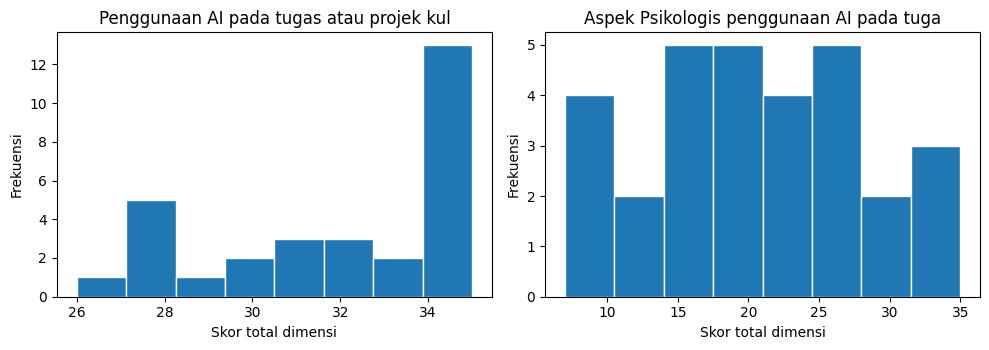

,Dimensi,Rerata,SD,Skewness,z skew,Kurtosis,z kurt,Shapiro p
0,Penggunaan AI pada tugas atau projek kuliah,32.03,2.85,-0.526,-1.23,-1.057,-1.27,0.002
1,Aspek Psikologis penggunaan AI pada tugas atau...,20.03,7.78,0.018,0.04,-0.690,-0.83,0.581


,STS,TS,N,S,SS
Penggunaan AI pada tugas atau projek kuliah,0,4,2,73,131
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,58,49,7,56,40


In [21]:
# Sel TAMBAHAN 2 - distribusi data: frekuensi, histogram, skewness, kurtosis

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, len(dim_pilih), figsize=(5*len(dim_pilih), 3.6))
ax = np.atleast_1d(ax)
n_ = len(num_l)
se_s = np.sqrt(6*n_*(n_-1)/((n_-2)*(n_+1)*(n_+3)))
se_k = 2*se_s*np.sqrt((n_**2-1)/((n_-3)*(n_+5)))
baris = []
for a, d in zip(ax, dim_pilih):
    tot = num_l[dimensi[d]].sum(axis=1)
    a.hist(tot, bins=8, edgecolor="white")
    a.set_title(d[:40]); a.set_xlabel("Skor total dimensi"); a.set_ylabel("Frekuensi")
    sk, ku = stats.skew(tot, bias=False), stats.kurtosis(tot, bias=False)
    baris.append({"Dimensi": d, "Rerata": round(tot.mean(), 2), "SD": round(tot.std(ddof=1), 2),
                  "Skewness": round(sk, 3), "z skew": round(sk/se_s, 2),
                  "Kurtosis": round(ku, 3), "z kurt": round(ku/se_k, 2),
                  "Shapiro p": round(stats.shapiro(tot).pvalue, 3)})
plt.tight_layout(); plt.show()
display(pd.DataFrame(baris))

# frekuensi seluruh jawaban per dimensi (bukan probabilitas)
frek = {d: pd.Series(num_l[dimensi[d]].values.ravel()).value_counts().reindex([1,2,3,4,5], fill_value=0)
        for d in dim_pilih}
display(pd.DataFrame(frek).T.rename(columns={1:"STS",2:"TS",3:"N",4:"S",5:"SS"}))

In [22]:
# Sel TAMBAHAN 3 - Latihan 2: jumlah butir valid (r hitung vs corrected r >= 0,30)

r_tabel_30 = stats.t.ppf(0.975, n_-2) / np.sqrt((n_-2) + stats.t.ppf(0.975, n_-2)**2)
tv = tabel_validitas[tabel_validitas["Dimensi"].isin(dim_pilih)]
print("r tabel =", round(r_tabel_30, 3))
print("Valid (r hitung > r tabel)     :", int((tv["r hitung"] > r_tabel_30).sum()), "dari", len(tv))
print("Valid (corrected r >= 0,30)    :", int((tv["Corrected r"] >= 0.30).sum()), "dari", len(tv))
print("Tiga butir terlemah:"); display(tv.sort_values("Corrected r").head(3))

r tabel = 0.361
Valid (r hitung > r tabel)     : 14 dari 14
Valid (corrected r >= 0,30)    : 14 dari 14
Tiga butir terlemah:


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.554,0.424,0.0015,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.627,0.481,0.0002,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.722,0.495,0.0000,Valid


In [26]:
# Sel TAMBAHAN 4 - Latihan 3: buang satu butir lalu bandingkan alpha dimensi

dim_hapus, idx_hapus = dim_pilih[0], 3
x = num[dimensi[dim_hapus]]
kolom_hapus = dimensi[dim_hapus][idx_hapus]
print("Butir dibuang:", kolom_hapus)
print("Alpha sebelum:", round(cronbach_alpha(x), 4), "| jumlah butir:", x.shape[1])
x2 = x.drop(columns=kolom_hapus)
print("Alpha sesudah:", round(cronbach_alpha(x2), 4), "| jumlah butir:", x2.shape[1])
tot2 = x2.sum(axis=1); rt = r_tabel_30
display(pd.DataFrame({"r hitung": [round(stats.pearsonr(x2[c], tot2)[0], 3) for c in x2.columns],
                      "Valid": [stats.pearsonr(x2[c], tot2)[0] > rt for c in x2.columns]}, index=x2.columns.str[-40:]))

Butir dibuang: Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk memahami materi kuliah yang belum saya kuasai.]
Alpha sebelum: 0.7991 | jumlah butir: 7
Alpha sesudah: 0.7909 | jumlah butir: 6


,r hitung,Valid
i mendapatkan tugas atau projek kuliah.],0.792,True
l atau permasalahan dalam tugas kuliah.],0.696,True
asi saat mengerjakan tugas atau projek.],0.657,True
"kuliah, misalnya laporan atau makalah.]",0.756,True
ki kode program pada tugas atau projek.],0.797,True
menyelesaikan tugas atau projek kuliah.],0.605,True


In [27]:
# sel TAMBAHAN 5 - Latihan 4: pengaruh ukuran sampel

def r_tab(n):
    t = stats.t.ppf(0.975, n-2); return t/np.sqrt((n-2)+t**2)
hasil = []
for m in (10, 15, 20, 25, 30):
    s = num_l.sample(m, random_state=1) if m < 30 else num_l
    nv, tdk = 0, []
    for d in dim_pilih:
        xs = s[dimensi[d]]; tt = xs.sum(axis=1)
        for i, c in enumerate(dimensi[d], 1):
            r = stats.pearsonr(xs[c], tt)[0]
            if r > r_tab(m): nv += 1
            else: tdk.append(f"{d[:12]}-B{i} (r={r:.3f})")
    hasil.append({"n": m, "r tabel": round(r_tab(m), 3), "butir valid": nv, "butir tidak valid": "; ".join(tdk) or "-"})
display(pd.DataFrame(hasil))

,n,r tabel,butir valid,butir tidak valid
0,10,0.632,11,Penggunaan A-B2 (r=0.486); Penggunaan A-B4 (r=...
1,15,0.514,11,Penggunaan A-B2 (r=0.467); Penggunaan A-B4 (r=...
2,20,0.444,13,Penggunaan A-B4 (r=0.421)
3,25,0.396,14,-
4,30,0.361,14,-
